# BƯỚC 5 – LÀM SẠCH VÀ PHÂN TÍCH DỮ LIỆU (EDA)

Nguồn dữ liệu: MongoDB Atlas, database `CGV_data`, collection `cgv_final`.

Notebook gồm: làm sạch dữ liệu, xử lý giá trị thiếu, phân tích đơn biến và đa biến, trực quan hóa kết quả.


# Sản phẩm đầu ra

- Dữ liệu đã làm sạch và kiểm tra trước/sau xử lý.
- Biểu đồ đơn biến và đa biến có tiêu đề, nhãn trục.
- Nhận xét ngắn nêu ý nghĩa của từng biểu đồ.


## 1. Thư viện và cấu hình

Nếu thiếu `missingno`, cài bằng `%pip install missingno` rồi khởi động lại kernel.


In [33]:
import os
import re
import getpass
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno

from pymongo import MongoClient
from scipy.stats import skew, kurtosis, gaussian_kde

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)

print("Thư viện đã sẵn sàng.")


Thư viện đã sẵn sàng.


## 2. Kết nối MongoDB và tải dữ liệu

Sử dụng database `CGV_data`, collection `showtimes_v2`. Notebook đọc URI từ biến môi trường `MONGODB_URI`; nếu chưa có, sẽ yêu cầu nhập URI.


In [34]:
import os
import getpass
import certifi
from pymongo import MongoClient

MONGODB_URI = os.getenv("MONGODB_URI")

if not MONGODB_URI:
    MONGODB_URI = getpass.getpass("Nhập MongoDB Atlas URI: ")

DB_NAME = "CGV_data"
COLLECTION_NAME = "cgv_final"

client = MongoClient(
    MONGODB_URI,
    serverSelectionTimeoutMS=10000,
    tlsCAFile=certifi.where(),
)

client.admin.command("ping")  # Xác nhận kết nối
collection = client[DB_NAME][COLLECTION_NAME]

print("Kết nối MongoDB Atlas thành công!")
print("Database:", DB_NAME)
print("Collection:", COLLECTION_NAME)
print("Số document:", collection.count_documents({}))

Kết nối MongoDB Atlas thành công!
Database: CGV_data
Collection: cgv_final
Số document: 1172


In [35]:
# Tải toàn bộ document từ MongoDB về DataFrame
docs = list(collection.find({}))

df_raw = pd.DataFrame(docs)

# _id là khóa do MongoDB tạo tự động; không cần dùng trong EDA
if "_id" in df_raw.columns:
    df_raw = df_raw.drop(columns=["_id"])

print("Kích thước dữ liệu:", df_raw.shape)
display(df_raw.head())


Kích thước dữ liệu: (1172, 17)


,MovieName,Cinema,ShowDate,Format,ShowTime,GeneratedText,TicketPrice,AvailableSeats,TotalSeats,MovieURL,Rating,Director,Actors,Genre,ReleaseDate,Duration,Language
0,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU LẠI),CGV Crescent Mall,01/10/2026,2D Phụ Đề Việt | Rạp Lamour,10:30,Tôi đã có cơ hội xem suất chiếu AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT tại r...,65000,72,100,https://www.cgv.vn/default/avengers-endgame-encore.html,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, Chris Hemsworth, Scarlett Joha...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",25/09/2026,183 phút,Tiếng Anh với phụ đề tiếng Việt
1,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU LẠI),CGV Crescent Mall,01/10/2026,2D Phụ Đề Việt | Rạp Lamour,16:00,"Hôm nay, tôi có cơ hội tham gia vào một trải nghiệm thú vị khi xem suất chiế...",70000,65,100,https://www.cgv.vn/default/avengers-endgame-encore.html,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, Chris Hemsworth, Scarlett Joha...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",25/09/2026,183 phút,Tiếng Anh với phụ đề tiếng Việt
2,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU LẠI),CGV Crescent Mall,01/10/2026,2D Phụ Đề Việt | Rạp Lamour,21:30,Tôi đã có cơ hội xem suất chiếu AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT tại r...,75000,53,100,https://www.cgv.vn/default/avengers-endgame-encore.html,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, Chris Hemsworth, Scarlett Joha...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",25/09/2026,183 phút,Tiếng Anh với phụ đề tiếng Việt
3,CHIIKAWA: BÍ MẬT ĐẢO NGƯỜI CÁ,CGV Crescent Mall,01/10/2026,2D Phụ Đề Anh & Việt,18:00,"Hôm nay, tôi đã có cơ hội đến rạp chiếu CGV Crescent Mall để xem phim CHIIKA...",80000,79,100,https://www.cgv.vn/default/chiikawa-the-movie.html,p,Kei Oikawa,"Haruka Aoki, Makoto Tanaka, Ari Ozawa, Yuka Iguchi, Takayuki Asai, Yuma Uchi...",Hoạt Hình,28/08/2026,99 phút,Tiếng Nhật với phụ đề Việt & Anh; Lồng tiếng Việt
4,HÒN ĐẢO QUÊN LÃNG,CGV Crescent Mall,01/10/2026,2D Lồng Tiếng Việt,19:40,"Tôi vừa có cơ hội xem suất chiếu ""HÒN ĐẢO QUÊN LÃNG"" tại rạp chiếu CGV Cresc...",75000,67,100,https://www.cgv.vn/default/forgotten-island.html,K,Joel Crawford; Januel Mercado,"H.E.R., Liza Soberano, Dave Franco, Jenny Slate, Manny Jacinto, Dolly de Leo...","Hoạt Hình, Phiêu Lưu",25/09/2026,109 phút,Phụ đề Tiếng Việt & Lồng Tiếng Việt


## 3. Kiểm tra dữ liệu ban đầu


In [36]:
print("Số dòng:", df_raw.shape[0])
print("Số cột :", df_raw.shape[1])
print("\nTên cột:")
print(df_raw.columns.tolist())

print("\nKiểu dữ liệu:")
display(df_raw.dtypes.to_frame("dtype"))

print("\n5 dòng đầu:")
display(df_raw.head())


Số dòng: 1172
Số cột : 17

Tên cột:
['MovieName', 'Cinema', 'ShowDate', 'Format', 'ShowTime', 'GeneratedText', 'TicketPrice', 'AvailableSeats', 'TotalSeats', 'MovieURL', 'Rating', 'Director', 'Actors', 'Genre', 'ReleaseDate', 'Duration', 'Language']

Kiểu dữ liệu:


,dtype
MovieName,object
Cinema,object
ShowDate,object
Format,object
ShowTime,object
GeneratedText,object
TicketPrice,int64
AvailableSeats,int64
TotalSeats,int64
MovieURL,object



5 dòng đầu:


,MovieName,Cinema,ShowDate,Format,ShowTime,GeneratedText,TicketPrice,AvailableSeats,TotalSeats,MovieURL,Rating,Director,Actors,Genre,ReleaseDate,Duration,Language
0,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU LẠI),CGV Crescent Mall,01/10/2026,2D Phụ Đề Việt | Rạp Lamour,10:30,Tôi đã có cơ hội xem suất chiếu AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT tại r...,65000,72,100,https://www.cgv.vn/default/avengers-endgame-encore.html,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, Chris Hemsworth, Scarlett Joha...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",25/09/2026,183 phút,Tiếng Anh với phụ đề tiếng Việt
1,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU LẠI),CGV Crescent Mall,01/10/2026,2D Phụ Đề Việt | Rạp Lamour,16:00,"Hôm nay, tôi có cơ hội tham gia vào một trải nghiệm thú vị khi xem suất chiế...",70000,65,100,https://www.cgv.vn/default/avengers-endgame-encore.html,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, Chris Hemsworth, Scarlett Joha...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",25/09/2026,183 phút,Tiếng Anh với phụ đề tiếng Việt
2,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU LẠI),CGV Crescent Mall,01/10/2026,2D Phụ Đề Việt | Rạp Lamour,21:30,Tôi đã có cơ hội xem suất chiếu AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT tại r...,75000,53,100,https://www.cgv.vn/default/avengers-endgame-encore.html,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, Chris Hemsworth, Scarlett Joha...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",25/09/2026,183 phút,Tiếng Anh với phụ đề tiếng Việt
3,CHIIKAWA: BÍ MẬT ĐẢO NGƯỜI CÁ,CGV Crescent Mall,01/10/2026,2D Phụ Đề Anh & Việt,18:00,"Hôm nay, tôi đã có cơ hội đến rạp chiếu CGV Crescent Mall để xem phim CHIIKA...",80000,79,100,https://www.cgv.vn/default/chiikawa-the-movie.html,p,Kei Oikawa,"Haruka Aoki, Makoto Tanaka, Ari Ozawa, Yuka Iguchi, Takayuki Asai, Yuma Uchi...",Hoạt Hình,28/08/2026,99 phút,Tiếng Nhật với phụ đề Việt & Anh; Lồng tiếng Việt
4,HÒN ĐẢO QUÊN LÃNG,CGV Crescent Mall,01/10/2026,2D Lồng Tiếng Việt,19:40,"Tôi vừa có cơ hội xem suất chiếu ""HÒN ĐẢO QUÊN LÃNG"" tại rạp chiếu CGV Cresc...",75000,67,100,https://www.cgv.vn/default/forgotten-island.html,K,Joel Crawford; Januel Mercado,"H.E.R., Liza Soberano, Dave Franco, Jenny Slate, Manny Jacinto, Dolly de Leo...","Hoạt Hình, Phiêu Lưu",25/09/2026,109 phút,Phụ đề Tiếng Việt & Lồng Tiếng Việt


## 4. Chuẩn hóa kiểu dữ liệu

`ShowDate` và `ReleaseDate` được chuyển sang kiểu ngày; `Duration` được tách thành số phút. Giữ `df_before` để đối chiếu trước và sau xử lý thiếu.


In [37]:
df = df_raw.copy()

# Chuẩn hóa chuỗi: biến các chuỗi rỗng thành NaN
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].replace(r"^\s*$", np.nan, regex=True)

# Parse ngày tháng
for col in ["ShowDate", "ReleaseDate"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], format="%d/%m/%Y", errors="coerce")

# Tách số phút từ Duration, ví dụ: "183 phút" -> 183
if "Duration" in df.columns:
    df["DurationMinutes"] = (
        df["Duration"]
        .astype("string")
        .str.extract(r"(\d+(?:\.\d+)?)", expand=False)
        .astype(float)
    )

# Mốc Before được chụp sau chuẩn hóa kiểu dữ liệu nhưng trước khi impute.
df_before = df.copy()

print("Các kiểu dữ liệu sau chuẩn hóa:")
display(df.dtypes.to_frame("dtype"))


Các kiểu dữ liệu sau chuẩn hóa:


,dtype
MovieName,object
Cinema,object
ShowDate,datetime64[ns]
Format,object
ShowTime,object
GeneratedText,object
TicketPrice,int64
AvailableSeats,int64
TotalSeats,int64
MovieURL,object


# 5. Xử lý giá trị thiếu

## 5.1. Thống kê giá trị thiếu

Đếm số lượng và tỷ lệ giá trị thiếu theo từng cột.


In [38]:
missing_before = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().mean() * 100).round(2)
}).sort_values("Missing_Count", ascending=False)

display(missing_before)


,Missing_Count,Missing_Percent
MovieName,0,0.0
Cinema,0,0.0
Language,0,0.0
Duration,0,0.0
ReleaseDate,0,0.0
Genre,0,0.0
Actors,0,0.0
Director,0,0.0
Rating,0,0.0
MovieURL,0,0.0


In [39]:
# Trực quan hóa missing values bằng missingno.
missing_plot = missing_before[missing_before["Missing_Count"] > 0]

if missing_plot.empty:
    print("Không phát hiện giá trị thiếu trong dữ liệu.")
else:
    msno.matrix(df, figsize=(12, 5), sparkline=False, fontsize=9)
    plt.title("Missing-value matrix trước khi imputation")
    plt.tight_layout()
    plt.show()

    msno.bar(df, figsize=(12, 5), sort="descending", fontsize=9)
    plt.title("Số giá trị hiện có theo cột trước khi imputation")
    plt.tight_layout()
    plt.show()


Không phát hiện giá trị thiếu trong dữ liệu.


## 5.2. Cách điền giá trị thiếu

- Biến số: Median.
- Biến phân loại: Mode; nếu không có, dùng `Unknown`.
- Ngày tháng: giữ thiếu nếu không có căn cứ nghiệp vụ.
- `DurationMinutes`: xử lý như biến số.


In [40]:
# Lưu thống kê numerical trước imputation để đối chiếu
numeric_candidates = df.select_dtypes(include=np.number).columns.tolist()
before_numeric_stats = (
    df_before[numeric_candidates].describe().T
    if numeric_candidates
    else pd.DataFrame()
)

# Numerical: Median ít nhạy với ngoại lệ hơn Mean.
for col in numeric_candidates:
    missing_count = int(df[col].isna().sum())
    if missing_count == 0:
        continue

    median_value = df[col].median()
    if pd.notna(median_value):
        df[col] = df[col].fillna(median_value)
        print(f"{col}: điền {missing_count} giá trị thiếu bằng Median = {median_value}")
    else:
        print(f"{col}: toàn bộ giá trị thiếu, không thể tính Median để điền.")

# Categorical: Mode; nếu cột không có giá trị quan sát được thì dùng Unknown.
categorical_cols = df.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

for col in categorical_cols:
    missing_count = int(df[col].isna().sum())
    if missing_count == 0:
        continue

    mode_series = df[col].mode(dropna=True)
    fill_value = mode_series.iloc[0] if not mode_series.empty else "Unknown"
    df[col] = df[col].fillna(fill_value)
    print(f"{col}: điền {missing_count} giá trị thiếu bằng Mode/Unknown = {fill_value}")

print("Datetime không được điền tự động; xem xét riêng theo ý nghĩa nghiệp vụ ở mục 5.3.")


Datetime không được điền tự động; xem xét riêng theo ý nghĩa nghiệp vụ ở mục 5.3.


### 5.3. Dữ liệu thời gian

Không tự điền ngày cho `ShowDate` hoặc `ReleaseDate`. Chỉ thử `ffill()`/`bfill()` trên bản sao khi phù hợp với thứ tự thời gian và nghiệp vụ.


In [41]:
date_cols = [c for c in ["ShowDate", "ReleaseDate"] if c in df.columns]

for col in date_cols:
    missing_count = df[col].isna().sum()
    print(f"{col}: {missing_count} giá trị thiếu")

# Minh họa ffill/bfill trên bản sao, chỉ dùng khi nghiệp vụ cho phép.
df_time_demo = df[date_cols].copy()

if date_cols:
    df_time_demo_ffill = df_time_demo.ffill()
    df_time_demo_bfill = df_time_demo.bfill()
    print("\nĐã tạo 2 bản minh họa ffill và bfill.")
    print("Không dùng hai bản này để thay thế ngày gốc nếu không có căn cứ nghiệp vụ.")


ShowDate: 0 giá trị thiếu
ReleaseDate: 0 giá trị thiếu

Đã tạo 2 bản minh họa ffill và bfill.
Không dùng hai bản này để thay thế ngày gốc nếu không có căn cứ nghiệp vụ.


## 5.4. Đối chiếu trước và sau xử lý

So sánh số giá trị thiếu và thống kê biến số trước/sau khi điền.


,Before_Count,After_Count
MovieName,0,0
Cinema,0,0
ShowDate,0,0
Format,0,0
ShowTime,0,0
GeneratedText,0,0
TicketPrice,0,0
AvailableSeats,0,0
TotalSeats,0,0
MovieURL,0,0


,Variable,Missing_Before,Missing_After,Mean_Before,Mean_After,Median_Before,Median_After,Std_Before,Std_After
0,TicketPrice,0,0,79709.898,79709.898,75000.0,75000.0,12230.052,12230.052
1,AvailableSeats,0,0,67.051,67.051,66.0,66.0,15.572,15.572
2,TotalSeats,0,0,100.887,100.887,100.0,100.0,8.584,8.584
3,DurationMinutes,0,0,127.211,127.211,135.0,135.0,25.666,25.666


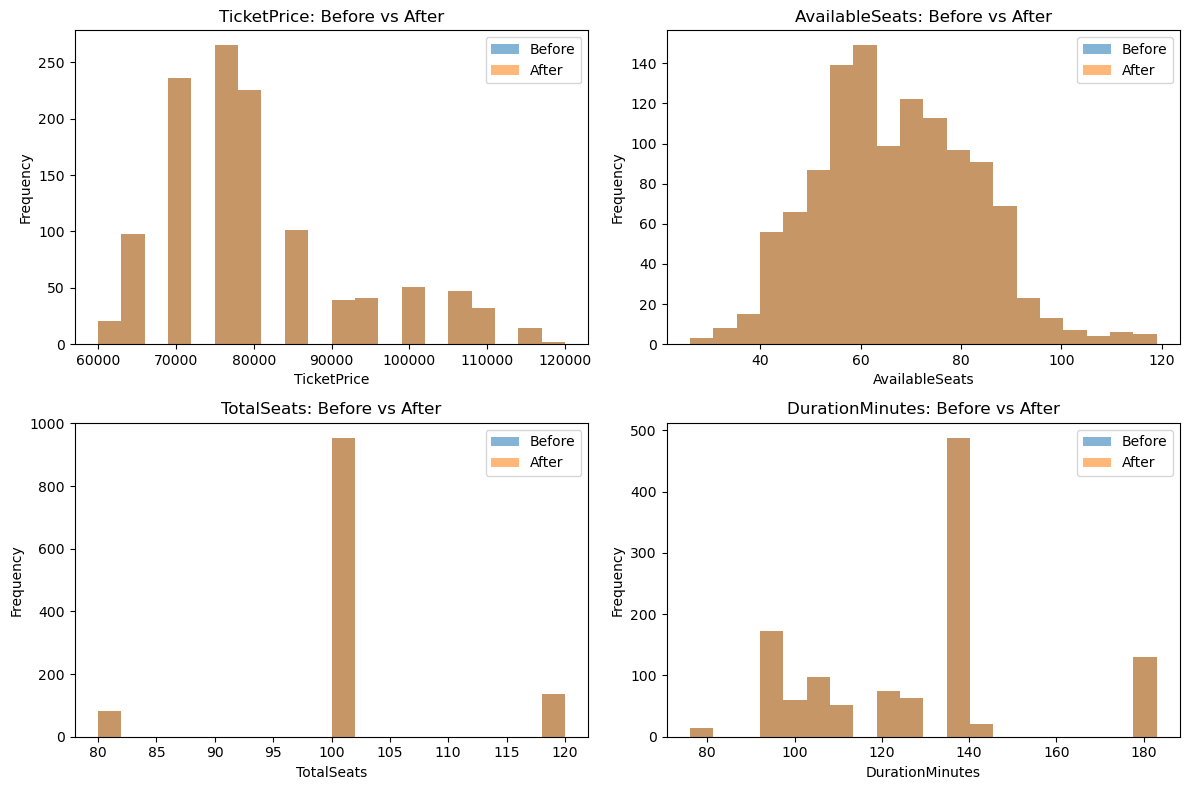

In [42]:
missing_after = pd.DataFrame({
    "Before_Count": df_before.isna().sum(),
    "After_Count": df.isna().sum()
})

display(missing_after)

# Đối chiếu thống kê và phân phối của tất cả biến số trước/sau imputation.
comparison_rows = []
for col in numeric_candidates:
    before = pd.to_numeric(df_before[col], errors="coerce")
    after = pd.to_numeric(df[col], errors="coerce")
    comparison_rows.append({
        "Variable": col,
        "Missing_Before": int(before.isna().sum()),
        "Missing_After": int(after.isna().sum()),
        "Mean_Before": before.mean(),
        "Mean_After": after.mean(),
        "Median_Before": before.median(),
        "Median_After": after.median(),
        "Std_Before": before.std(),
        "Std_After": after.std(),
    })

if comparison_rows:
    comparison = pd.DataFrame(comparison_rows)
    display(comparison.round(3))

    ncols = 2
    nrows = int(np.ceil(len(numeric_candidates) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows))
    axes = np.asarray(axes).reshape(-1)

    for ax, col in zip(axes, numeric_candidates):
        before_values = pd.to_numeric(df_before[col], errors="coerce").dropna()
        after_values = pd.to_numeric(df[col], errors="coerce").dropna()
        if not before_values.empty:
            ax.hist(before_values, bins=20, alpha=0.55, label="Before")
        if not after_values.empty:
            ax.hist(after_values, bins=20, alpha=0.55, label="After")
        ax.set_title(f"{col}: Before vs After")
        ax.set_xlabel(col)
        ax.set_ylabel("Frequency")
        ax.legend()

    for ax in axes[len(numeric_candidates):]:
        ax.set_visible(False)

    fig.tight_layout()
    plt.show()
else:
    print("Không có biến số để so sánh phân phối trước/sau imputation.")


# 6. Phân tích đơn biến

## 6.1. Phân loại biến

Biến số gồm các trường định lượng như `DurationMinutes`; biến phân loại gồm `MovieName`, `Cinema`, `Format`, `Rating`, `Genre`, `Language` và các trường tương tự.


In [43]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

# Chọn các categorical phù hợp để tránh phân tích quá nhiều trường văn bản dài
preferred_categorical = [
    "MovieName", "Cinema", "Format", "Rating", "Genre", "Language"
]
categorical_analysis_cols = [
    c for c in preferred_categorical if c in df.columns
]

print("Biến số:", numeric_cols)
print("Biến phân loại dùng trong EDA:", categorical_analysis_cols)


Biến số: ['TicketPrice', 'AvailableSeats', 'TotalSeats', 'DurationMinutes']
Biến phân loại dùng trong EDA: ['MovieName', 'Cinema', 'Format', 'Rating', 'Genre', 'Language']


## 6.2. Thống kê mô tả

Tính Mean, Median, độ lệch chuẩn, Skewness và Kurtosis.


In [44]:
if numeric_cols:
    rows = []
    for col in numeric_cols:
        s = pd.to_numeric(df[col], errors="coerce").dropna()
        rows.append({
            "Variable": col,
            "Mean": s.mean(),
            "Median": s.median(),
            "Std": s.std(),
            "Skewness": skew(s) if len(s) > 2 else np.nan,
            "Kurtosis": kurtosis(s) if len(s) > 3 else np.nan,
            "Min": s.min(),
            "Max": s.max()
        })

    univariate_numeric_stats = pd.DataFrame(rows)
    display(univariate_numeric_stats.round(3))
else:
    print("Không có biến số để phân tích.")


,Variable,Mean,Median,Std,Skewness,Kurtosis,Min,Max
0,TicketPrice,79709.898,75000.0,12230.052,1.078,0.612,60000.0,120000.0
1,AvailableSeats,67.051,66.0,15.572,0.278,-0.073,26.0,119.0
2,TotalSeats,100.887,100.0,8.584,0.251,2.324,80.0,120.0
3,DurationMinutes,127.211,135.0,25.666,0.629,0.188,76.0,183.0


## 6.3. Histogram và KDE

Quan sát phân phối của các biến số.


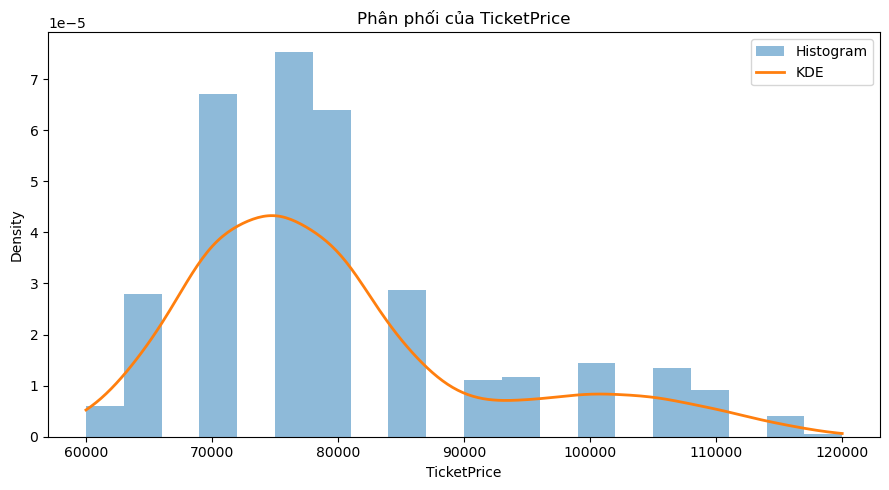

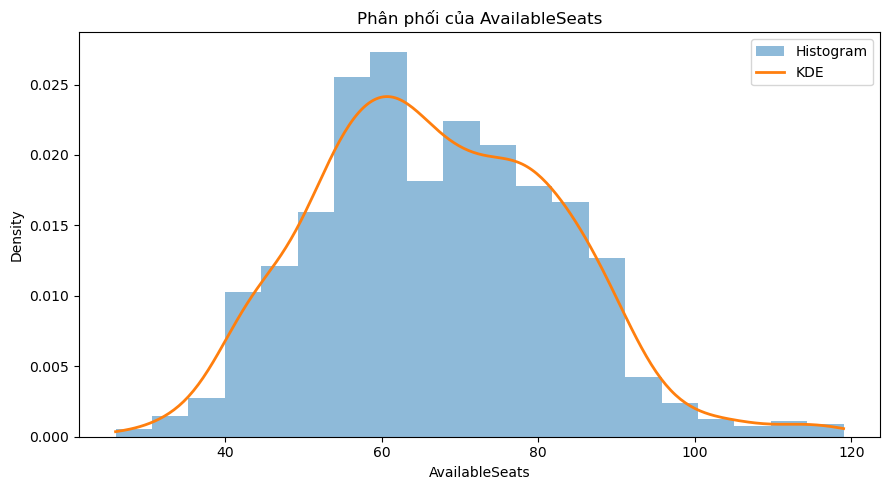

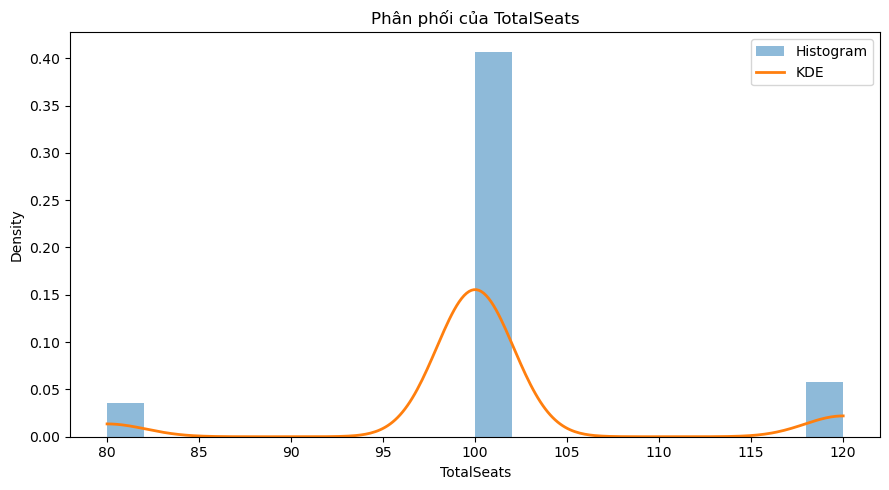

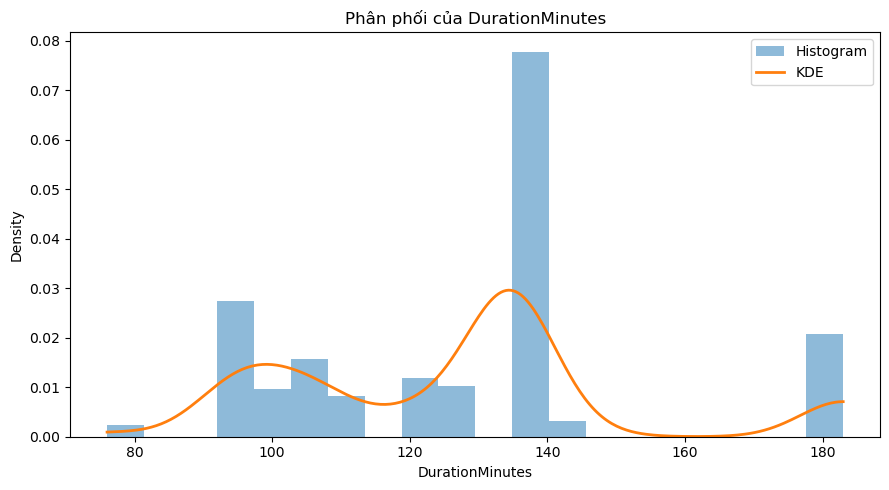

In [45]:
for col in numeric_cols:
    values = pd.to_numeric(df[col], errors="coerce").dropna()

    plt.figure(figsize=(9, 5))
    plt.hist(values, bins=20, density=True, alpha=0.5, label="Histogram")

    # KDE bằng scipy
    if values.nunique() > 1 and len(values) > 2:
        x = np.linspace(values.min(), values.max(), 300)
        kde = gaussian_kde(values)
        plt.plot(x, kde(x), linewidth=2, label="KDE")

    plt.xlabel(col)
    plt.ylabel("Density")
    plt.title(f"Phân phối của {col}")
    plt.legend()
    plt.tight_layout()
    plt.show()


## 6.4. Ngoại lệ theo IQR

Dùng ngưỡng `Q1 − 1.5 × IQR` và `Q3 + 1.5 × IQR`. Chỉ capping `TicketPrice` và `DurationMinutes` trên bản sao; không tự sửa các biến đếm hợp lệ.


In [46]:
iqr_results = []
continuous_iqr_cols = [
    col for col in ["TicketPrice", "DurationMinutes"] if col in numeric_cols
]
df_iqr_treated = df.copy()

for col in numeric_cols:
    s = pd.to_numeric(df[col], errors="coerce").dropna()

    if s.empty:
        iqr_results.append({
            "Variable": col,
            "Q1": np.nan,
            "Q3": np.nan,
            "IQR": np.nan,
            "Lower_Bound": np.nan,
            "Upper_Bound": np.nan,
            "Outlier_Count": 0,
            "Outlier_Percent": 0.0,
            "Treatment": "Không đủ dữ liệu",
            "Treated_Count": 0,
        })
        continue

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_mask = (s < lower) | (s > upper)
    treated_count = 0

    if col in continuous_iqr_cols:
        capped = s.clip(lower=lower, upper=upper)
        treated_count = int((capped != s).sum())
        df_iqr_treated.loc[s.index, col] = capped
        treatment = "IQR capping trên bản sao phân tích"
    else:
        treatment = "Giữ nguyên biến đếm; xác minh theo nghiệp vụ"

    iqr_results.append({
        "Variable": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Outlier_Count": int(outlier_mask.sum()),
        "Outlier_Percent": round(outlier_mask.mean() * 100, 2),
        "Treatment": treatment,
        "Treated_Count": treated_count,
    })

iqr_table = pd.DataFrame(iqr_results)
display(iqr_table.round(3))

# Kiểm tra ràng buộc nghiệp vụ để phân biệt ngoại lệ thống kê với dữ liệu sai.
if {"AvailableSeats", "TotalSeats"}.issubset(df.columns):
    available = pd.to_numeric(df["AvailableSeats"], errors="coerce")
    total = pd.to_numeric(df["TotalSeats"], errors="coerce")
    invalid_seat_mask = (
        available.isna()
        | total.isna()
        | available.lt(0)
        | total.le(0)
        | available.gt(total)
    )
    print(f"Số dòng vi phạm ràng buộc 0 <= AvailableSeats <= TotalSeats: {int(invalid_seat_mask.sum())}")
    if invalid_seat_mask.any():
        display(df.loc[invalid_seat_mask, ["AvailableSeats", "TotalSeats"]])
    else:
        print("Các giá trị số ghế nằm trong miền hợp lệ; giữ nguyên dù bị IQR đánh dấu.")

print("Dữ liệu gốc df không bị thay đổi; bản xử lý ngoại lệ nằm trong df_iqr_treated.")


,Variable,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percent,Treatment,Treated_Count
0,TicketPrice,70000.0,85000.0,15000.0,47500.0,107500.0,48,4.10,IQR capping trên bản sao phân tích,48
1,AvailableSeats,56.0,78.0,22.0,23.0,111.0,11,0.94,Giữ nguyên biến đếm; xác minh theo nghiệp vụ,0
2,TotalSeats,100.0,100.0,0.0,100.0,100.0,218,18.60,Giữ nguyên biến đếm; xác minh theo nghiệp vụ,0
3,DurationMinutes,103.0,135.0,32.0,55.0,183.0,0,0.00,IQR capping trên bản sao phân tích,0


Số dòng vi phạm ràng buộc 0 <= AvailableSeats <= TotalSeats: 0
Các giá trị số ghế nằm trong miền hợp lệ; giữ nguyên dù bị IQR đánh dấu.
Dữ liệu gốc df không bị thay đổi; bản xử lý ngoại lệ nằm trong df_iqr_treated.


**Nhận xét 6.4:**
- `TicketPrice`: 48 suất (4,10%) vượt ngưỡng 107.500 đồng. Đó là suất phòng đặc biệt (4DX, IMAX, ScreenX, GOLD CLASS...) nên là giá trị **hợp lệ về nghiệp vụ**, không phải lỗi. Capping trên bản sao chỉ nên dùng để so sánh, **không nên** áp cho dữ liệu huấn luyện vì sẽ xóa mất chênh lệch giá của phòng cao cấp.
- `TotalSeats`: IQR = 0 (đa số phòng 100 ghế) nên 218 suất (18,6%) phòng 80 hoặc 120 ghế bị đánh dấu. Đây là cỡ phòng thật nên giữ nguyên.
- `AvailableSeats`: 11 suất (0,94%) ngoài ngưỡng; toàn bộ vẫn trong 0 ≤ AvailableSeats ≤ TotalSeats nên giữ nguyên.
- `DurationMinutes`: không có ngoại lệ.

## 6.5. Boxplot biến số


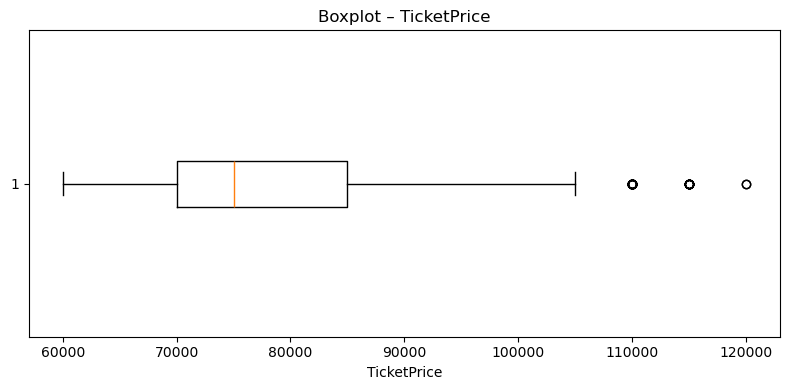

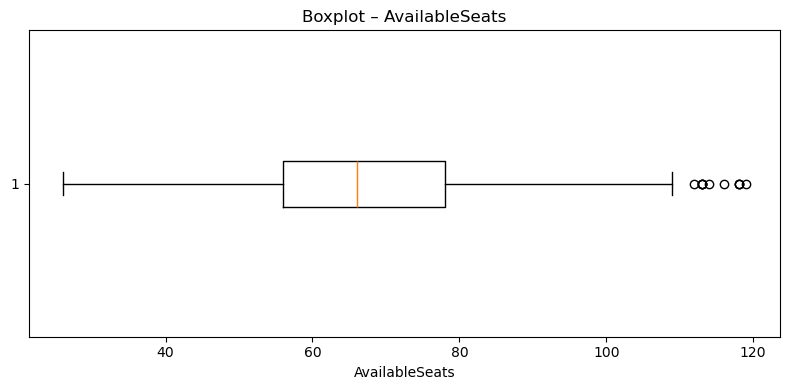

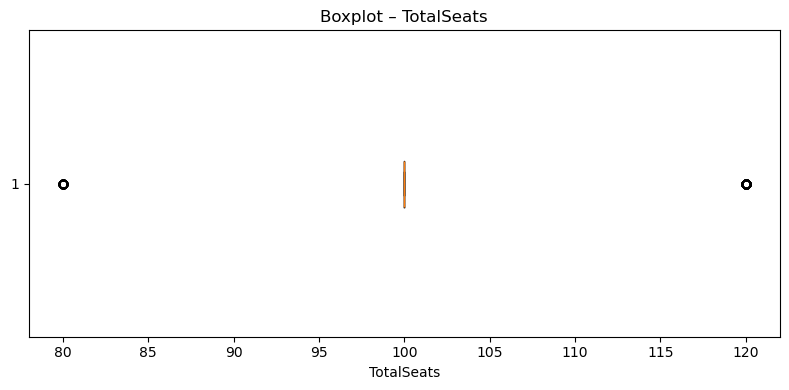

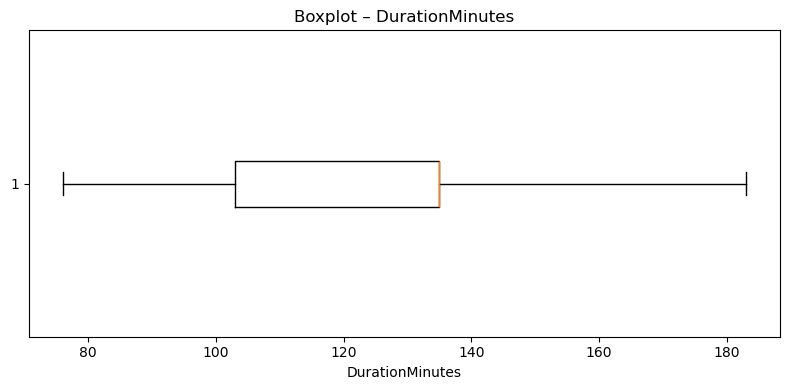

In [47]:
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    plt.boxplot(pd.to_numeric(df[col], errors="coerce").dropna(), vert=False)
    plt.xlabel(col)
    plt.title(f"Boxplot – {col}")
    plt.tight_layout()
    plt.show()


## 6.6. Tần số biến phân loại

Thống kê số lượng và tỷ lệ của từng nhóm.


In [48]:
categorical_frequency = {}

for col in categorical_analysis_cols:
    freq = df[col].value_counts(dropna=False)
    pct = (df[col].value_counts(normalize=True, dropna=False) * 100)

    table = pd.DataFrame({
        "Frequency": freq,
        "Percent": pct.round(2)
    })

    categorical_frequency[col] = table
    print(f"\n===== {col} =====")
    display(table.head(20))



===== MovieName =====


,Frequency,Percent
MovieName,,
TRẠI BUÔN NGƯỜI,488,41.64
AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU LẠI),130,11.09
VÙNG ĐẤT QUỶ DỮ,110,9.39
LÊN HƯƠNG,74,6.31
LAPUTA: LÂU ĐÀI TRÊN KHÔNG,64,5.46
ÁN MẠNG KARAOKE,60,5.12
TRÁI TIM QUÁI THÚ,54,4.61
HÒN ĐẢO QUÊN LÃNG,51,4.35
MARNIE YÊU DẤU,49,4.18



===== Cinema =====


,Frequency,Percent
Cinema,,
CGV Crescent Mall,297,25.34
CGV Hùng Vương Plaza,297,25.34
CGV Vivo City,272,23.21
CGV Thảo Điền Pearl,215,18.34
CGV Vincom Thủ Đức,91,7.76



===== Format =====


,Frequency,Percent
Format,,
2D Phụ Đề Anh,569,48.55
2D Phụ Đề Việt,289,24.66
2D Phụ Đề Anh & Việt,41,3.50
2D Phụ Đề Anh | Rạp GOLD CLASS,35,2.99
2D Lồng Tiếng Việt,33,2.82
2D Phụ Đề Anh | Rạp Cine & Living Room,32,2.73
IMAX2D Phụ Đề Việt | Rạp IMAX,27,2.30
4DX2D Phụ Đề Việt | Rạp 4DX\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t & Infinity Vision,26,2.22
4DX2D Phụ Đề Anh | Rạp 4DX,24,2.05


... (2 outputs left out)


===== Genre =====


,Frequency,Percent
Genre,,
"Hành Động, Hồi hộp",488,41.64
Hoạt Hình,134,11.43
"Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",130,11.09
"Hành Động, Kinh Dị",110,9.39
"Gia đình, Tâm Lý",74,6.31
"Hài, Hồi hộp",60,5.12
Hành Động,54,4.61
"Hoạt Hình, Phiêu Lưu",51,4.35
Kinh Dị,49,4.18



===== Language =====


,Frequency,Percent
Language,,
Tiếng Việt,624,53.24
Tiếng Anh - Phụ đề Tiếng Việt,164,13.99
Tiếng Anh với phụ đề tiếng Việt,130,11.09
Tiếng Nhật - Phụ đề Tiếng Việt; Lồng Tiếng Việt,113,9.64
Phụ đề Tiếng Việt & Lồng Tiếng Việt,51,4.35
Vietnamese,49,4.18
Tiếng Trung Quốc - Phụ đề Tiếng Việt,20,1.71
Phụ đề tiếng Việt & tiếng Anh,15,1.28
Tiếng Nhật với phụ đề Việt & Anh; Lồng tiếng Việt,6,0.51


## 6.7. Bar chart biến phân loại

Hiển thị 10 nhóm xuất hiện nhiều nhất.


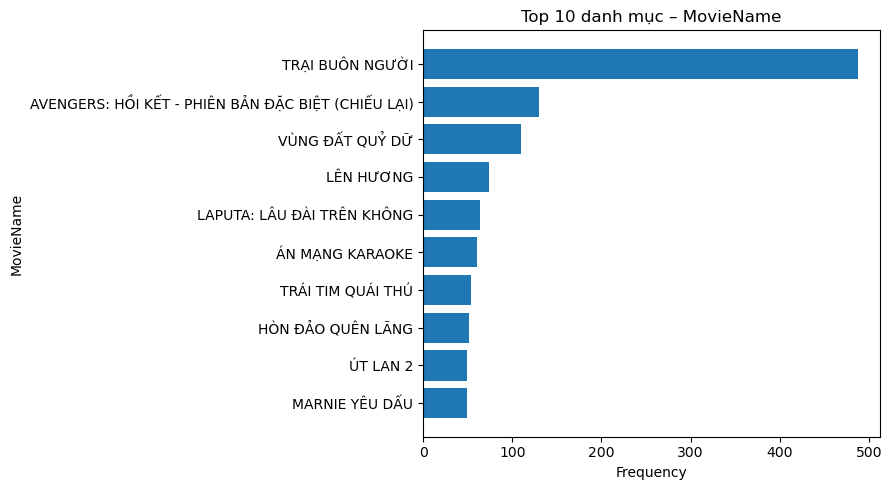

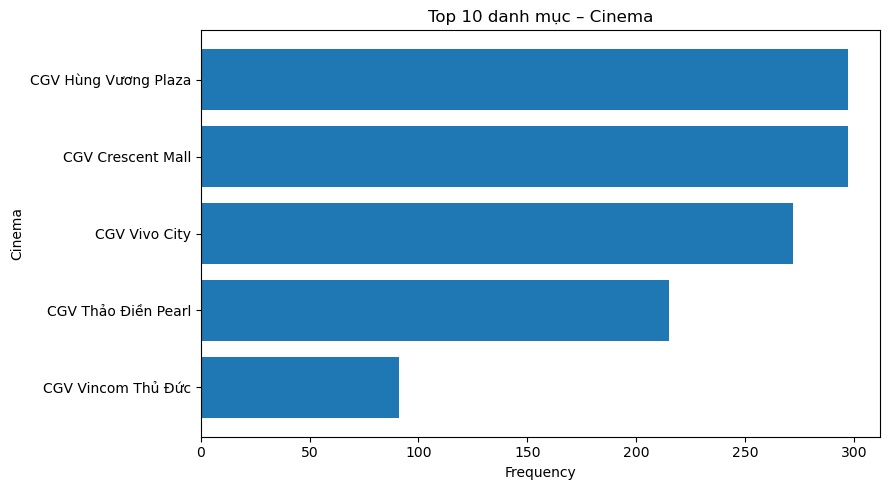

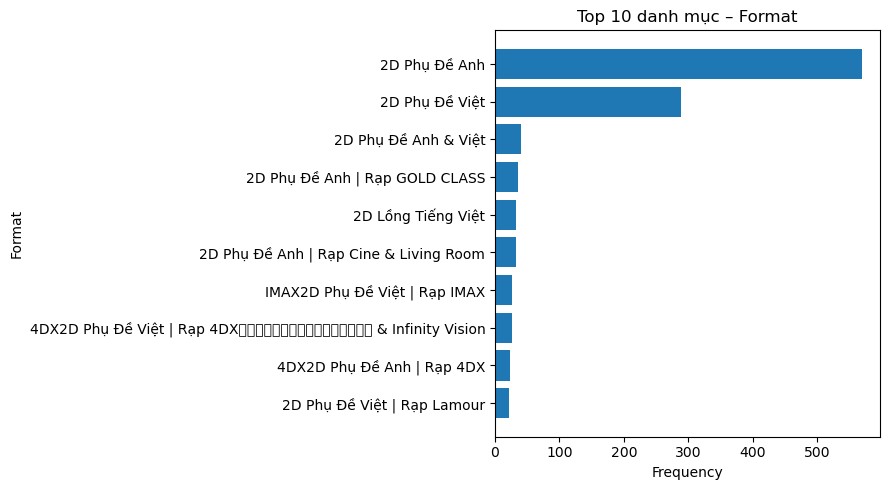

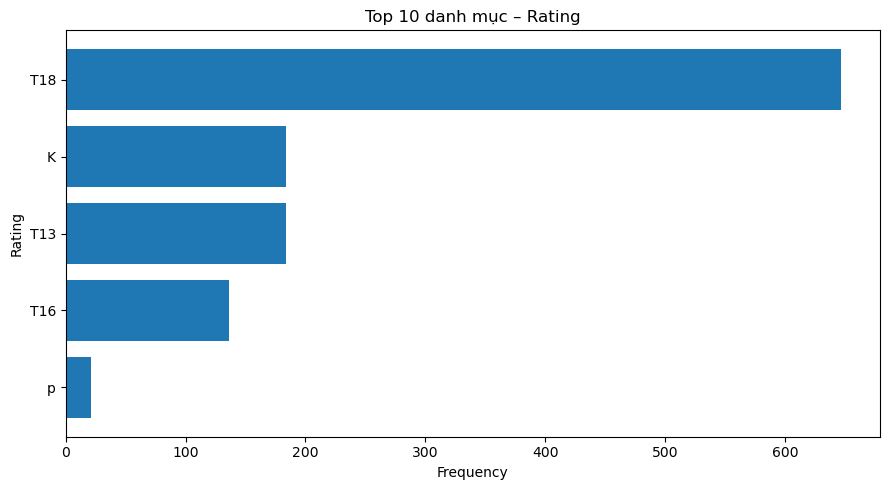

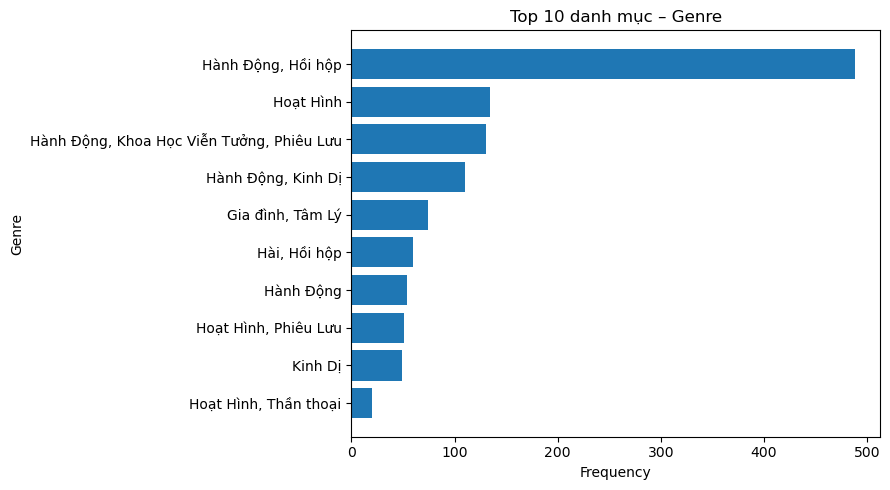

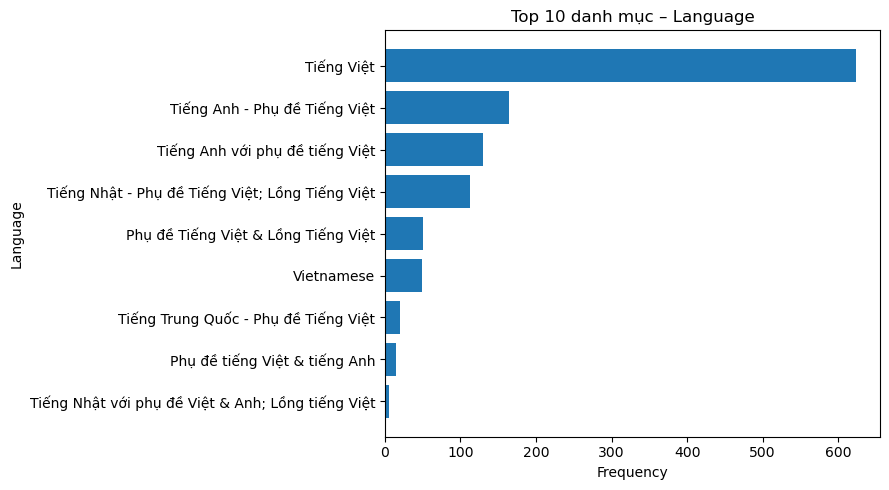

In [49]:
for col in categorical_analysis_cols:
    counts = df[col].value_counts().head(10).sort_values()

    plt.figure(figsize=(9, 5))
    plt.barh(counts.index.astype(str), counts.values)
    plt.xlabel("Frequency")
    plt.ylabel(col)
    plt.title(f"Top 10 danh mục – {col}")
    plt.tight_layout()
    plt.show()


**Nhận xét 6.6–6.7:** Dữ liệu tập trung vào vài phim và vài định dạng. 'Trại buồn người' chiếm 41,6% số suất, 3 phim đứng đầu chiếm khoảng 62%; định dạng '2D Phụ Đề Anh' chiếm khoảng 49%. 5 rạp chia khá đều, trừ CGV Vincom Thủ Đức chỉ 7,8%. Cột `Format` còn lẫn ký tự tab (`\t`) nên cần làm sạch trước khi mã hóa; nhãn tuổi `p` (21 suất) cần chuẩn hóa thành `P` để không bị tách thành nhóm riêng.

# 7. Phân tích đa biến

## 7.1. Tương quan Pearson và Spearman

Pearson đo quan hệ tuyến tính; Spearman đo quan hệ đơn điệu. Mỗi cặp biến dùng các dòng có dữ liệu hợp lệ.


In [50]:
analysis_df = pd.DataFrame(index=df.index)

for col in ["TicketPrice", "AvailableSeats", "TotalSeats", "DurationMinutes"]:
    if col in df.columns:
        analysis_df[col] = pd.to_numeric(df[col], errors="coerce")

if "ShowTime" in df.columns:
    analysis_df["ShowHour"] = pd.to_datetime(
        df["ShowTime"].astype("string").str.strip(),
        format="%H:%M",
        errors="coerce",
    ).dt.hour

if {"ShowDate", "ReleaseDate"}.issubset(df.columns):
    analysis_df["DaysFromReleaseToShow"] = (
        pd.to_datetime(df["ShowDate"], errors="coerce")
        - pd.to_datetime(df["ReleaseDate"], errors="coerce")
    ).dt.days

corr_cols = [
    col for col in analysis_df.columns
    if analysis_df[col].nunique(dropna=True) > 1
]

if len(corr_cols) >= 2:
    corr_data = analysis_df[corr_cols]
    corr_pearson = corr_data.corr(method="pearson")
    corr_spearman = corr_data.corr(method="spearman")
    pairwise_counts = corr_data.notna().astype(int).T.dot(
        corr_data.notna().astype(int)
    )
    corr = corr_pearson

    print("Ma trận tương quan Pearson:")
    display(corr_pearson.round(3))
    print("Ma trận tương quan Spearman:")
    display(corr_spearman.round(3))
    print("Số quan sát hợp lệ theo từng cặp biến:")
    display(pairwise_counts)
else:
    corr_pearson = pd.DataFrame()
    corr_spearman = pd.DataFrame()
    corr = pd.DataFrame()
    print("Không đủ ít nhất 2 biến số có dữ liệu để tính tương quan.")


Ma trận tương quan Pearson:


,TicketPrice,AvailableSeats,TotalSeats,DurationMinutes,ShowHour,DaysFromReleaseToShow
TicketPrice,1.000,0.019,0.290,0.317,0.263,-0.254
AvailableSeats,0.019,1.000,0.427,-0.161,-0.207,0.171
TotalSeats,0.290,0.427,1.000,0.247,0.003,-0.024
DurationMinutes,0.317,-0.161,0.247,1.000,0.000,-0.236
ShowHour,0.263,-0.207,0.003,0.000,1.000,-0.027
DaysFromReleaseToShow,-0.254,0.171,-0.024,-0.236,-0.027,1.000


Ma trận tương quan Spearman:


,TicketPrice,AvailableSeats,TotalSeats,DurationMinutes,ShowHour,DaysFromReleaseToShow
TicketPrice,1.000,-0.115,0.209,0.203,0.342,-0.340
AvailableSeats,-0.115,1.000,0.398,-0.255,-0.192,0.166
TotalSeats,0.209,0.398,1.000,0.155,0.001,-0.015
DurationMinutes,0.203,-0.255,0.155,1.000,0.003,-0.216
ShowHour,0.342,-0.192,0.001,0.003,1.000,-0.047
DaysFromReleaseToShow,-0.340,0.166,-0.015,-0.216,-0.047,1.000


Số quan sát hợp lệ theo từng cặp biến:


,TicketPrice,AvailableSeats,TotalSeats,DurationMinutes,ShowHour,DaysFromReleaseToShow
TicketPrice,1172,1172,1172,1172,1172,1172
AvailableSeats,1172,1172,1172,1172,1172,1172
TotalSeats,1172,1172,1172,1172,1172,1172
DurationMinutes,1172,1172,1172,1172,1172,1172
ShowHour,1172,1172,1172,1172,1172,1172
DaysFromReleaseToShow,1172,1172,1172,1172,1172,1172


**Nhận xét 7.1:** Pearson và Spearman cùng chiều ở hầu hết các cặp; chỉ `TicketPrice` – `AvailableSeats` đổi dấu (0,02 so với −0,12), cho thấy quan hệ yếu và không tuyến tính. `ShowHour` có tương quan dương với giá vé (Spearman 0,34): suất tối đắt hơn suất sáng. `ShowHour` cũng tương quan âm với số ghế trống (−0,19): suất tối đông khách hơn. Số quan sát hợp lệ ở mọi cặp là 1.172, không thiếu dữ liệu.

## 7.2. Heatmap tương quan


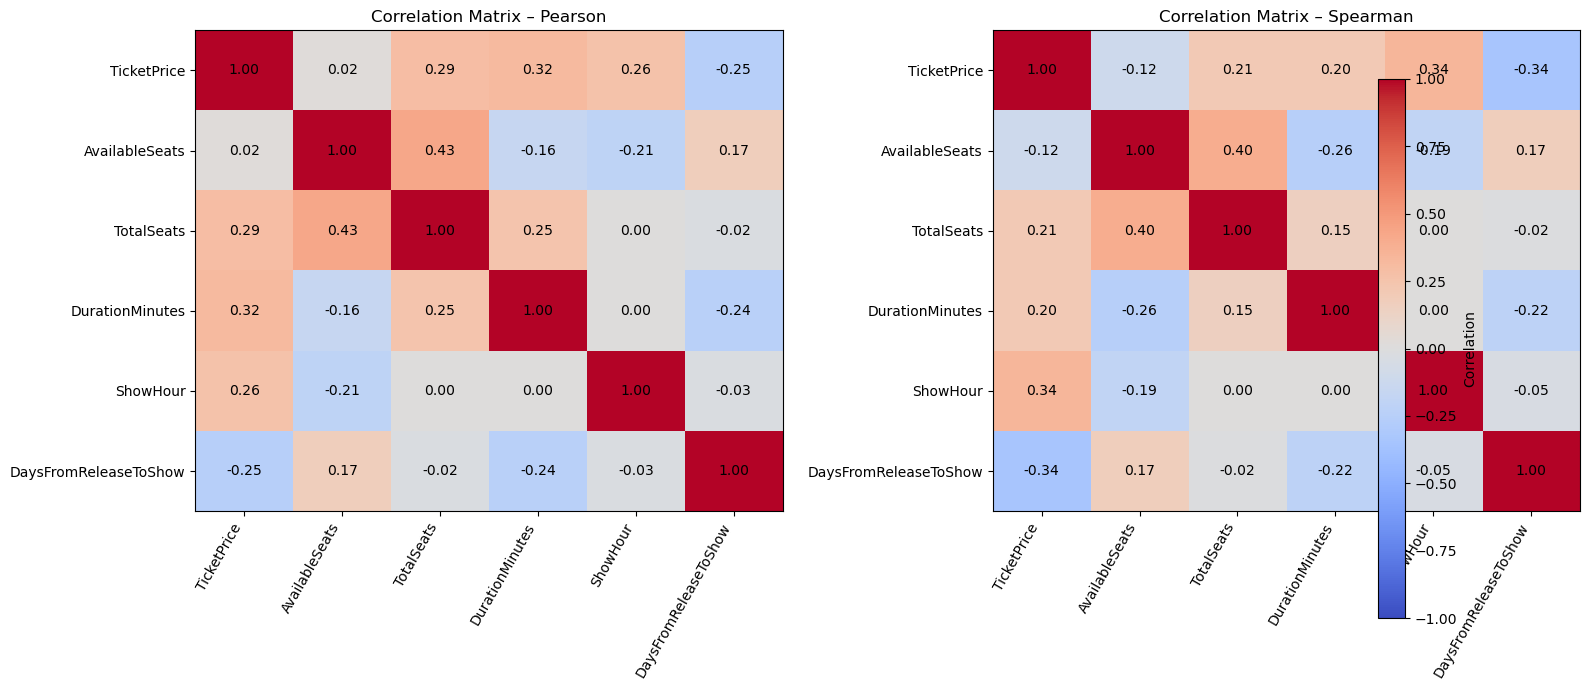

In [51]:
if not corr_pearson.empty:
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    for ax, matrix, title in zip(
        axes,
        [corr_pearson, corr_spearman],
        ["Pearson", "Spearman"],
    ):
        image = ax.imshow(
            matrix.to_numpy(),
            interpolation="nearest",
            aspect="auto",
            cmap="coolwarm",
            vmin=-1,
            vmax=1,
        )
        ax.set_xticks(range(len(matrix.columns)))
        ax.set_xticklabels(matrix.columns, rotation=60, ha="right")
        ax.set_yticks(range(len(matrix.index)))
        ax.set_yticklabels(matrix.index)

        for row in range(len(matrix.index)):
            for col in range(len(matrix.columns)):
                ax.text(
                    col,
                    row,
                    f"{matrix.iloc[row, col]:.2f}",
                    ha="center",
                    va="center",
                )

        ax.set_title(f"Correlation Matrix – {title}")

    fig.colorbar(image, ax=axes, fraction=0.046, pad=0.04, label="Correlation")
    fig.tight_layout()
    plt.show()
else:
    print("Không đủ biến số để vẽ Heatmap.")


## 7.3. Scatter plot

Vẽ các cặp biến số khi có ít nhất hai biến phù hợp.


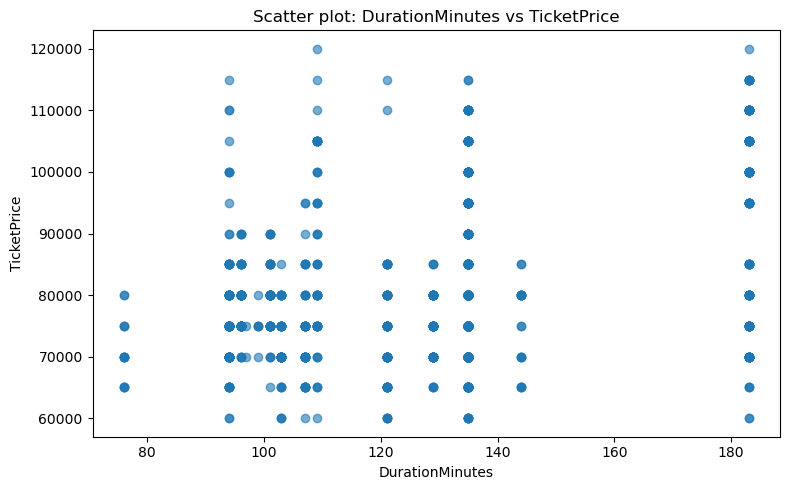

In [52]:
scatter_pair = [
    col for col in ["DurationMinutes", "TicketPrice"] if col in analysis_df.columns
]
if len(scatter_pair) < 2:
    scatter_pair = corr_cols[:2]

if len(scatter_pair) >= 2:
    x_col, y_col = scatter_pair
    plot_data = analysis_df[[x_col, y_col]].dropna()

    if len(plot_data) >= 2:
        plt.figure(figsize=(8, 5))
        plt.scatter(plot_data[x_col], plot_data[y_col], alpha=0.6)
        plt.xlabel(x_col)
        plt.ylabel(y_col)
        plt.title(f"Scatter plot: {x_col} vs {y_col}")
        plt.tight_layout()
        plt.show()
    else:
        print(f"Không đủ cặp dữ liệu hợp lệ để vẽ {x_col} vs {y_col}.")
else:
    print("Chưa có đủ 2 biến số để vẽ Scatter plot.")


**Nhận xét 7.4:** Thời lượng trung bình theo rạp chỉ chênh nhau khoảng 10 phút (CGV Vivo City 131,7 phút so với CGV Thảo Điền Pearl 121,9 phút). Điều này do rạp nào chiếu nhiều phim dài hay ngắn chứ không phải đặc điểm của rạp; trung vị ở ba rạp đầu đều bằng 135 phút.

## 7.4. Biến phân loại và biến số

So sánh thời lượng phim theo rạp bằng Mean, Median và Count.


Thống kê DurationMinutes theo Cinema:


,mean,median,count
Cinema,,,
CGV Vivo City,131.67,135.0,272
CGV Hùng Vương Plaza,131.45,135.0,297
CGV Vincom Thủ Đức,124.79,135.0,91
CGV Crescent Mall,123.46,129.0,297
CGV Thảo Điền Pearl,121.93,121.0,215


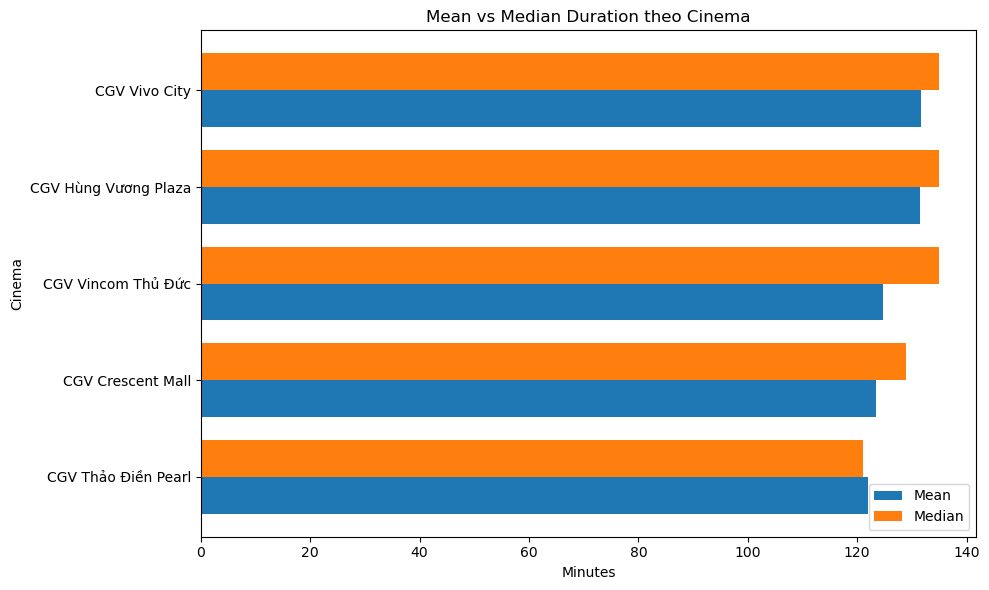

In [53]:
if "Cinema" in df.columns and "DurationMinutes" in df.columns:
    cinema_stats = (
        df.groupby("Cinema")["DurationMinutes"]
        .agg(["mean", "median", "count"])
        .sort_values("mean", ascending=False)
    )

    print("Thống kê DurationMinutes theo Cinema:")
    display(cinema_stats.round(2).head(20))

    top_cinemas = cinema_stats.head(10).index
    plot_data = cinema_stats.loc[top_cinemas].sort_values("mean")

    x = np.arange(len(plot_data))
    width = 0.38

    plt.figure(figsize=(10, 6))
    plt.barh(x - width/2, plot_data["mean"], height=width, label="Mean")
    plt.barh(x + width/2, plot_data["median"], height=width, label="Median")
    plt.yticks(x, plot_data.index.astype(str))
    plt.xlabel("Minutes")
    plt.ylabel("Cinema")
    plt.title("Mean vs Median Duration theo Cinema")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Thiếu Cinema hoặc DurationMinutes để phân tích.")


## 7.5. Bảng chéo biến phân loại

Ví dụ: phân bố `Format` theo `Cinema`.


Bảng chéo Cinema × Format:


Format,2D Lồng Tiếng Việt,2D Phụ Đề Anh,2D Phụ Đề Anh & Việt,2D Phụ Đề Anh | Rạp Cine & Living Room,2D Phụ Đề Anh | Rạp GOLD CLASS,2D Phụ Đề Anh | Rạp Lamour,2D Phụ Đề Anh | Rạp STARIUM,2D Phụ Đề Việt,2D Phụ Đề Việt\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t | Rạp Infinity Vision,2D Phụ Đề Việt | Rạp Cine & Living Room,2D Phụ Đề Việt | Rạp Lamour,2D Phụ Đề Việt | Rạp STARIUM,2D Phụ Đề Việt | Rạp STARIUM\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t & Infinity Vision,4DX2D Lồng Tiếng Việt | Rạp 4DX,4DX2D Phụ Đề Anh | Rạp 4DX,4DX2D Phụ Đề Việt | Rạp 4DX,4DX2D Phụ Đề Việt | Rạp 4DX\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t & Infinity Vision,IMAX2D Phụ Đề Việt | Rạp IMAX,SCREENX-2D Phụ Đề Việt | Rạp SCREENX,SCREENX-2D Phụ Đề Việt | Rạp SCREENX\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t\t & Infinity Vision
Cinema,,,,,,,,,,,,,,,,,,,,
CGV Crescent Mall,18,151,6,32,0,6,0,61,0,1,22,0,0,0,0,0,0,0,0,0
CGV Hùng Vương Plaza,1,154,0,0,35,0,0,45,0,0,0,0,0,6,12,0,13,0,12,19
CGV Thảo Điền Pearl,6,74,22,0,0,0,0,113,0,0,0,0,0,0,0,0,0,0,0,0
CGV Vincom Thủ Đức,8,59,0,0,0,0,7,13,0,0,0,2,2,0,0,0,0,0,0,0
CGV Vivo City,0,131,13,0,0,0,0,57,11,0,0,0,0,6,12,2,13,27,0,0


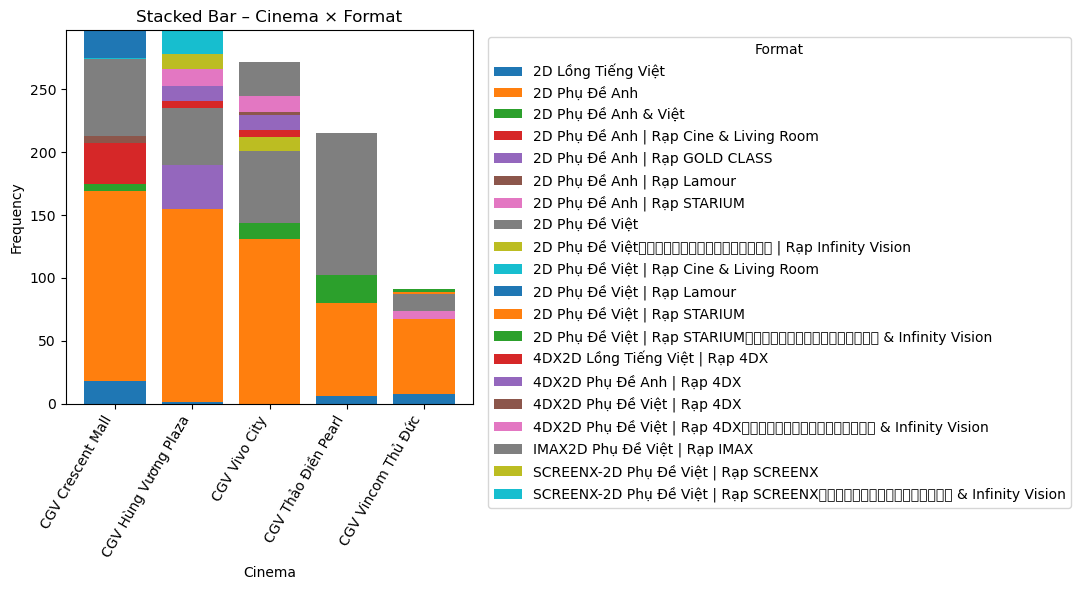

In [54]:
if "Cinema" in df.columns and "Format" in df.columns:
    crosstab = pd.crosstab(df["Cinema"], df["Format"])

    print("Bảng chéo Cinema × Format:")
    display(crosstab)

    # Vẽ Top 10 rạp theo tổng số suất chiếu
    top_rows = crosstab.sum(axis=1).sort_values(ascending=False).head(10).index
    plot_ct = crosstab.loc[top_rows]

    plt.figure(figsize=(11, 6))
    bottom = np.zeros(len(plot_ct))

    for category in plot_ct.columns:
        values = plot_ct[category].values
        plt.bar(plot_ct.index.astype(str), values, bottom=bottom, label=str(category))
        bottom += values

    plt.xticks(rotation=60, ha="right")
    plt.ylabel("Frequency")
    plt.xlabel("Cinema")
    plt.title("Stacked Bar – Cinema × Format")
    plt.legend(title="Format", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
else:
    print("Thiếu Cinema hoặc Format để tạo bảng chéo.")


## 7.6. Grouped bar chart

So sánh số suất chiếu theo định dạng phim giữa các rạp.


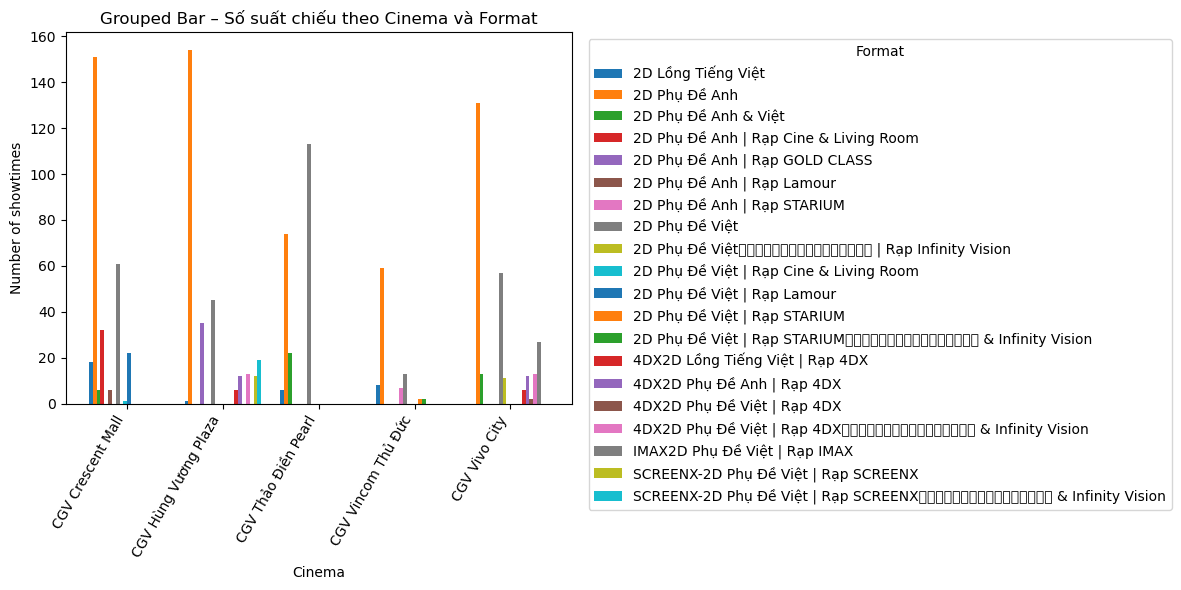

In [55]:
if "Cinema" in df.columns and "Format" in df.columns:
    top_cinemas = df["Cinema"].value_counts().head(8).index
    group_data = (
        df[df["Cinema"].isin(top_cinemas)]
        .groupby(["Cinema", "Format"])
        .size()
        .unstack(fill_value=0)
    )

    x = np.arange(len(group_data))
    formats = group_data.columns
    width = 0.8 / max(len(formats), 1)

    plt.figure(figsize=(12, 6))

    for i, fmt in enumerate(formats):
        plt.bar(
            x + (i - (len(formats)-1)/2) * width,
            group_data[fmt],
            width=width,
            label=str(fmt)
        )

    plt.xticks(x, group_data.index.astype(str), rotation=60, ha="right")
    plt.xlabel("Cinema")
    plt.ylabel("Number of showtimes")
    plt.title("Grouped Bar – Số suất chiếu theo Cinema và Format")
    plt.legend(title="Format", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
else:
    print("Thiếu Cinema hoặc Format để vẽ Grouped Bar.")


## 7.7. Grouped boxplot

So sánh `DurationMinutes` giữa các nhóm `Rating`.


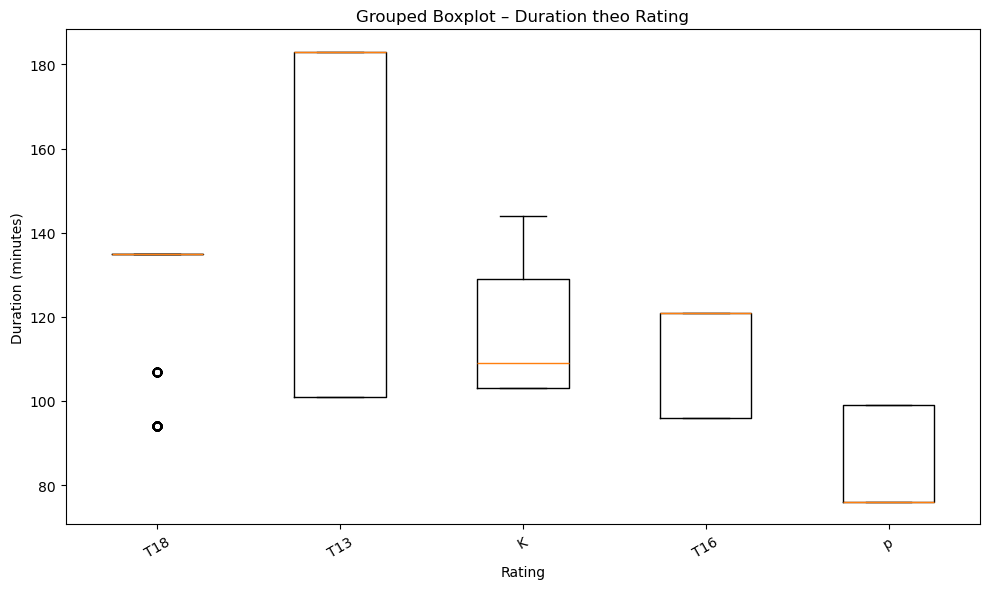

In [56]:
if "Rating" in df.columns and "DurationMinutes" in df.columns:
    box_data = []
    labels = []

    # Chọn các rating có đủ dữ liệu, tối đa 10 nhóm
    rating_counts = df["Rating"].value_counts().head(10)

    for rating in rating_counts.index:
        values = df.loc[df["Rating"] == rating, "DurationMinutes"].dropna()
        if len(values) > 0:
            box_data.append(values.values)
            labels.append(str(rating))

    if box_data:
        plt.figure(figsize=(10, 6))
        plt.boxplot(box_data, tick_labels=labels, showfliers=True)
        plt.xlabel("Rating")
        plt.ylabel("Duration (minutes)")
        plt.title("Grouped Boxplot – Duration theo Rating")
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()
    else:
        print("Không đủ dữ liệu để vẽ Grouped Boxplot.")
else:
    print("Thiếu Rating hoặc DurationMinutes.")


# 8. Tóm tắt EDA

Tạo báo cáo ngắn về các kết quả chính.


In [57]:
print("========== TÓM TẮT EDA ==========")
print(f"Số dòng sau khi tải từ MongoDB: {len(df_raw):,}")
print(f"Số cột phân tích: {df.shape[1]}")
print(f"Tổng số ô thiếu trước xử lý: {int(df_before.isna().sum().sum()):,}")
print(f"Tổng số ô thiếu sau xử lý: {int(df.isna().sum().sum()):,}")

if numeric_cols:
    for col in numeric_cols:
        s = pd.to_numeric(df[col], errors="coerce").dropna()
        print(
            f"- {col}: mean={s.mean():.2f}, median={s.median():.2f}, "
            f"std={s.std():.2f}"
        )

if "DurationMinutes" in df.columns:
    print(
        f"- DurationMinutes: min={df['DurationMinutes'].min():.0f}, "
        f"max={df['DurationMinutes'].max():.0f}"
    )

if "Cinema" in df.columns:
    print("- Cinema phổ biến nhất:", df["Cinema"].value_counts().idxmax())

if "Format" in df.columns:
    print("- Format phổ biến nhất:", df["Format"].value_counts().idxmax())

print("\nEDA đã hoàn tất.")


========== TÓM TẮT EDA ==========
Số dòng sau khi tải từ MongoDB: 1,172
Số cột phân tích: 18
Tổng số ô thiếu trước xử lý: 0
Tổng số ô thiếu sau xử lý: 0
- TicketPrice: mean=79709.90, median=75000.00, std=12230.05
- AvailableSeats: mean=67.05, median=66.00, std=15.57
- TotalSeats: mean=100.89, median=100.00, std=8.58
- DurationMinutes: mean=127.21, median=135.00, std=25.67
- DurationMinutes: min=76, max=183
- Cinema phổ biến nhất: CGV Crescent Mall
- Format phổ biến nhất: 2D Phụ Đề Anh

EDA đã hoàn tất.


# 9. Xuất dữ liệu đã xử lý

Lưu DataFrame thành CSV. Dữ liệu gốc vẫn được giữ trong `df_raw`.


In [58]:
OUTPUT_FILE = "cgv_eda_cleaned.csv"

df.to_csv(OUTPUT_FILE, index=False, encoding="utf-8-sig")

print(f"Đã lưu: {OUTPUT_FILE}")
print("Kích thước:", df.shape)


Đã lưu: cgv_eda_cleaned.csv
Kích thước: (1172, 18)


# 10. Checklist phân tích

| Nội dung | Kết quả |
|---|---|
| Kết nối và tải dữ liệu MongoDB | Đã thực hiện |
| Kiểm tra và trực quan hóa giá trị thiếu | Đã thực hiện |
| Điền thiếu cho biến số và phân loại | Đã thực hiện |
| So sánh trước/sau xử lý | Đã thực hiện |
| Thống kê, phân phối và ngoại lệ IQR | Đã thực hiện |
| Phân tích tương quan và biểu đồ đa biến | Đã thực hiện |

Notebook tải dữ liệu từ `showtimes_v2` và thực hiện các bước EDA trên.


# 11. Biểu đồ và nhận xét

Sáu biểu đồ dưới đây kèm nhận xét ngay bên dưới.


## Biểu đồ 1 – Phân phối thời lượng phim

Histogram và KDE của `DurationMinutes`.


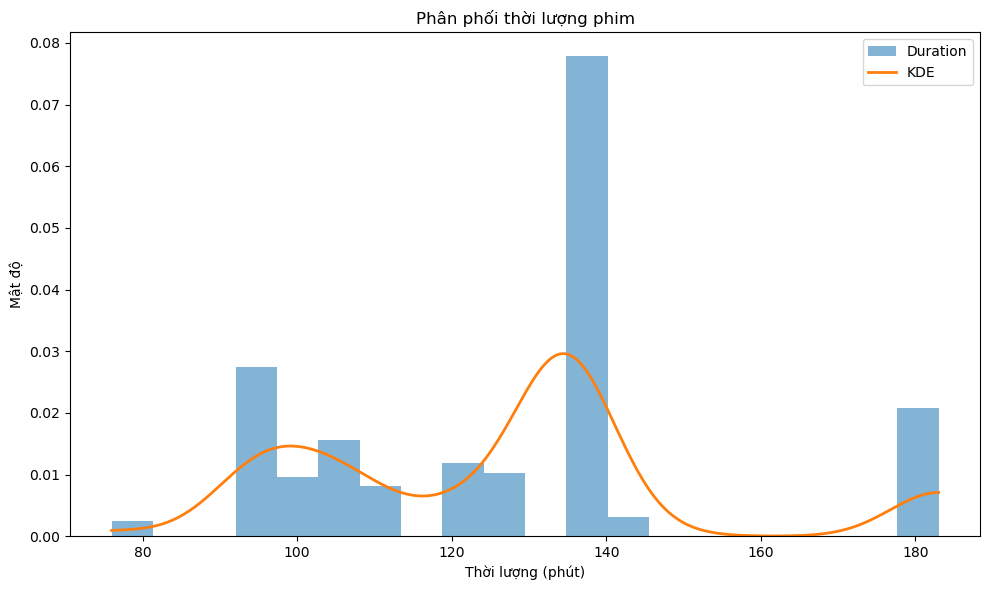

In [59]:
if 'DurationMinutes' in df.columns:
    values = pd.to_numeric(df['DurationMinutes'], errors='coerce').dropna()
    plt.figure(figsize=(10,6))
    plt.hist(values, bins=20, density=True, alpha=0.55, label='Duration')
    if len(values) >= 2 and values.nunique() > 1:
        from scipy.stats import gaussian_kde
        x = np.linspace(values.min(), values.max(), 300)
        kde = gaussian_kde(values)
        plt.plot(x, kde(x), linewidth=2, label='KDE')
    plt.title('Phân phối thời lượng phim')
    plt.xlabel('Thời lượng (phút)')
    plt.ylabel('Mật độ')
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Không tìm thấy cột DurationMinutes.')


### Nhận xét

- Thời lượng trung bình 127 phút, trung vị 135 phút, dao động 76–183 phút; phân phối hơi lệch phải (skewness ≈ 0,63).
- Đồ thị có nhiều đỉnh vì chỉ có 14 phim: mỗi phim có một thời lượng cố định và 'Trại buồn người' (135 phút) chiếm 41,6% số suất nên Q2 và Q3 đều bằng 135.
- Vì vậy `DurationMinutes` phản ánh cơ cấu phim hơn là một biến liên tục thực sự; khi đưa vào mô hình nên hiểu nó như đặc trưng của phim.

## Biểu đồ 2 – Ngoại lệ thời lượng phim


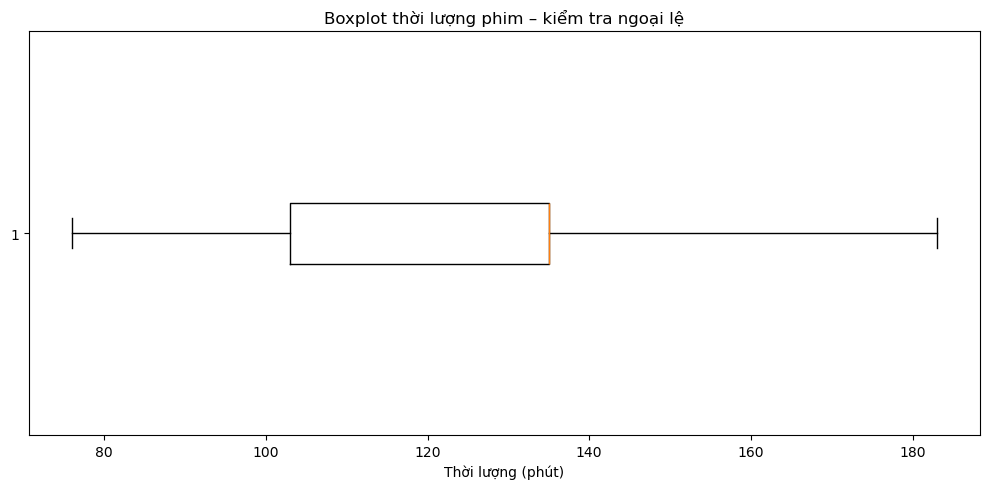

In [60]:
if 'DurationMinutes' in df.columns:
    values = pd.to_numeric(df['DurationMinutes'], errors='coerce').dropna()
    plt.figure(figsize=(10,5))
    plt.boxplot(values, vert=False)
    plt.title('Boxplot thời lượng phim – kiểm tra ngoại lệ')
    plt.xlabel('Thời lượng (phút)')
    plt.tight_layout()
    plt.show()
else:
    print('Không tìm thấy cột DurationMinutes.')


### Nhận xét

- IQR cho giới hạn trên đúng bằng 183 phút nên **không có ngoại lệ** nào ở thời lượng (0 điểm).
- Phim dài nhất (Avengers: Hồi kết, 183 phút) nằm đúng ở râu trên của boxplot, là giá trị hợp lệ về nghiệp vụ, không cần loại.

## Biểu đồ 3 – Top 10 thể loại phim


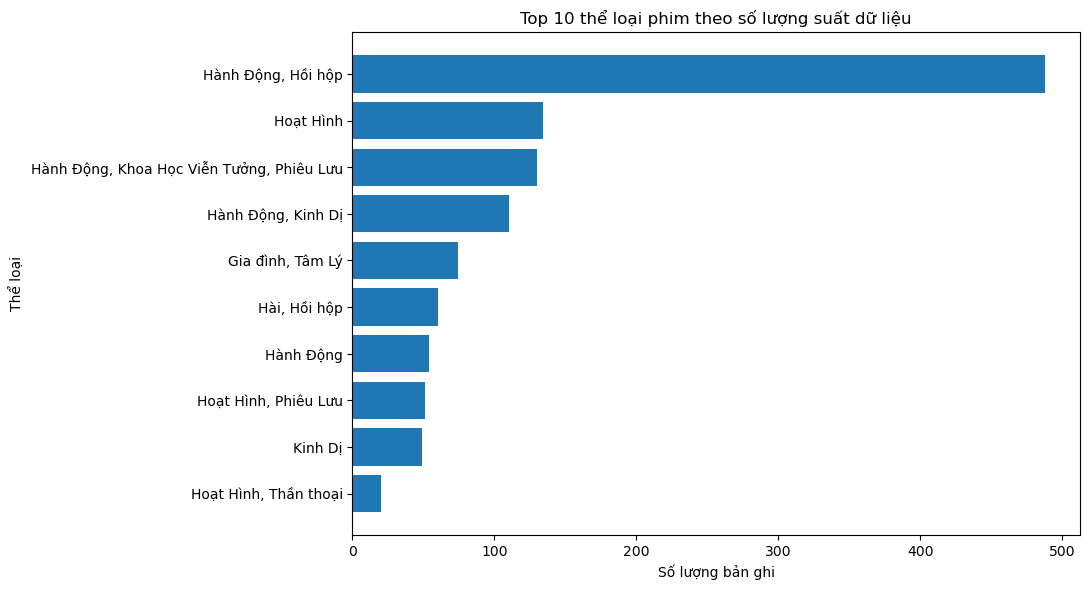

In [61]:
if 'Genre' in df.columns:
    counts = df['Genre'].astype(str).value_counts().head(10).sort_values()
    plt.figure(figsize=(11,6))
    plt.barh(counts.index, counts.values)
    plt.title('Top 10 thể loại phim theo số lượng suất dữ liệu')
    plt.xlabel('Số lượng bản ghi')
    plt.ylabel('Thể loại')
    plt.tight_layout()
    plt.show()
else:
    print('Không tìm thấy cột Genre.')


### Nhận xét

- Thể loại là chuỗi ghép nhiều nhãn: 'Hành Động, Hồi hộp' dẫn đầu với 488 suất (41,6%), tiếp theo là 'Hoạt Hình' (134), 'Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu' (130) và 'Hành Động, Kinh Dị' (110).
- Nhóm đầu gần như chỉ do một phim ('Trại buồn người') tạo ra nên biểu đồ này thể hiện cơ cấu lịch chiếu hơn là sở thích khán giả.
- Trước khi mã hóa cần tách `Genre` thành từng nhãn (Hành Động, Hồi hộp, Hoạt Hình...) để tránh hàng chục nhóm chỉ có vài dòng.

## Biểu đồ 4 – Heatmap tương quan


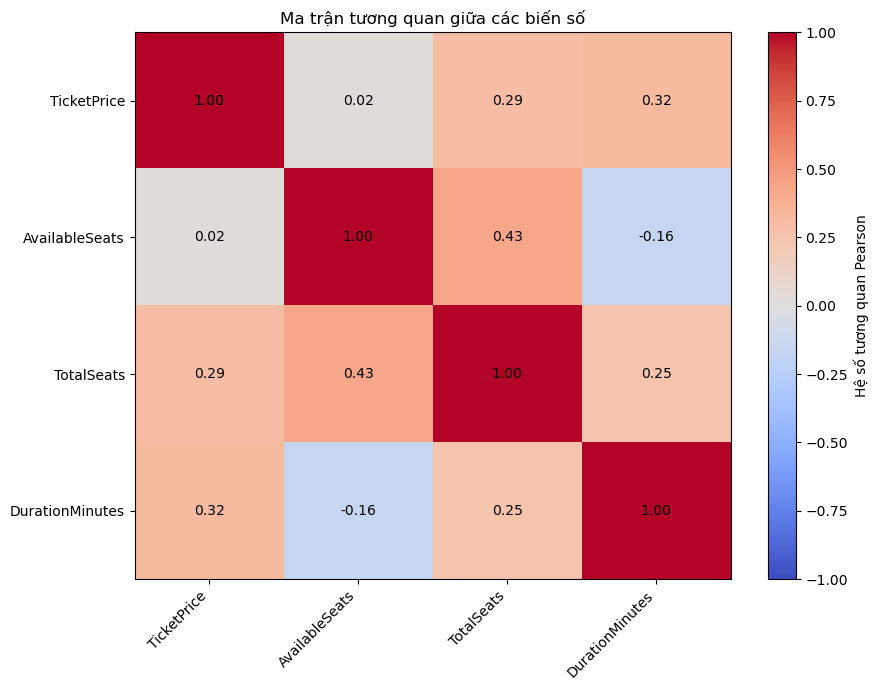

In [62]:
numeric_only_cols = df.select_dtypes(include=[np.number]).columns.tolist()

corr_cols_out = [c for c in numeric_only_cols if c not in ['_id']]

if len(corr_cols_out) >= 2:
    corr_out = df[corr_cols_out].corr(method='pearson')
    plt.figure(figsize=(9, 7))
    plt.imshow(corr_out, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
    plt.colorbar(label='Hệ số tương quan Pearson')
    plt.xticks(range(len(corr_out.columns)), corr_out.columns, rotation=45, ha='right')
    plt.yticks(range(len(corr_out.index)), corr_out.index)
    
    for i in range(len(corr_out.index)):
        for j in range(len(corr_out.columns)):
            plt.text(j, i, f'{corr_out.iloc[i, j]:.2f}', ha='center', va='center')
            
    plt.title('Ma trận tương quan giữa các biến số')
    plt.tight_layout()
    plt.show()
else:
    print('Chưa có đủ ít nhất 2 biến số (kiểu số) để tạo Heatmap tương quan.')

### Nhận xét

- Quan hệ rõ nhất: `AvailableSeats` – `TotalSeats` (r ≈ 0,43). Phòng nhiều ghế thì số ghế trống tuyệt đối lớn hơn; tỉ lệ lấp đầy gần như không đổi theo cỡ phòng (30–34%).
- `TicketPrice` tương quan vừa với `DurationMinutes` (r ≈ 0,32) và `TotalSeats` (r ≈ 0,29): phòng đặc biệt (IMAX, 4DX, ScreenX) có giá cao và hay chiếu phim bom tấn dài.
- `TicketPrice` – `AvailableSeats` gần như không tương quan tuyến tính (r ≈ 0,02), nhưng Spearman là −0,12 nên có chút quan hệ ngược chiều: giá cao thì ghế trống ít hơn một chút.
- Ba cột số là dữ liệu mô phỏng theo quy luật giả định nên các hệ số này phản ánh quy luật đã đặt cùng cấu trúc lịch chiếu, không phải hành vi khách thật. Tương quan cũng không chứng minh quan hệ nhân quả.

## Biểu đồ 5 – Thời lượng và khoảng cách ngày


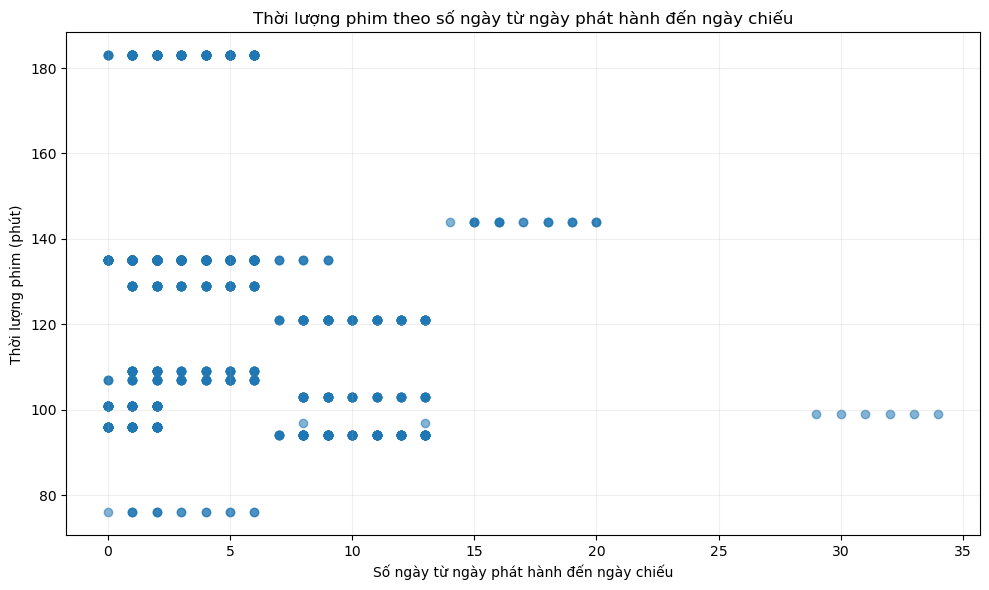

In [63]:
plot_df = analysis_df[["DurationMinutes", "DaysFromReleaseToShow"]].dropna()
plt.figure(figsize=(10, 6))
plt.scatter(
    plot_df["DaysFromReleaseToShow"], plot_df["DurationMinutes"], alpha=0.55
)
plt.title("Thời lượng phim theo số ngày từ ngày phát hành đến ngày chiếu")
plt.xlabel("Số ngày từ ngày phát hành đến ngày chiếu")
plt.ylabel("Thời lượng phim (phút)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### Nhận xét

- Phần lớn suất chiếu diễn ra trong 0–6 ngày sau ngày khởi chiếu (trung vị 4 ngày), nên các điểm dồn ở bên trái biểu đồ.
- Có quan hệ ngược nhẹ giữa số ngày và thời lượng (r ≈ −0,24): phim ra mắt gần đây là bom tấn dài, còn phim ra mắt lâu hơn thường ngắn hơn.
- Các điểm xa bên phải (tới 34 ngày) là phim chiếu lại hoặc phim ra mắt sớm hơn, vẫn là dữ liệu hợp lệ nhưng ít, cần thận trọng khi đưa `DaysFromReleaseToShow` vào mô hình.

## Biểu đồ 6 – Thời lượng theo Rating và thể loại


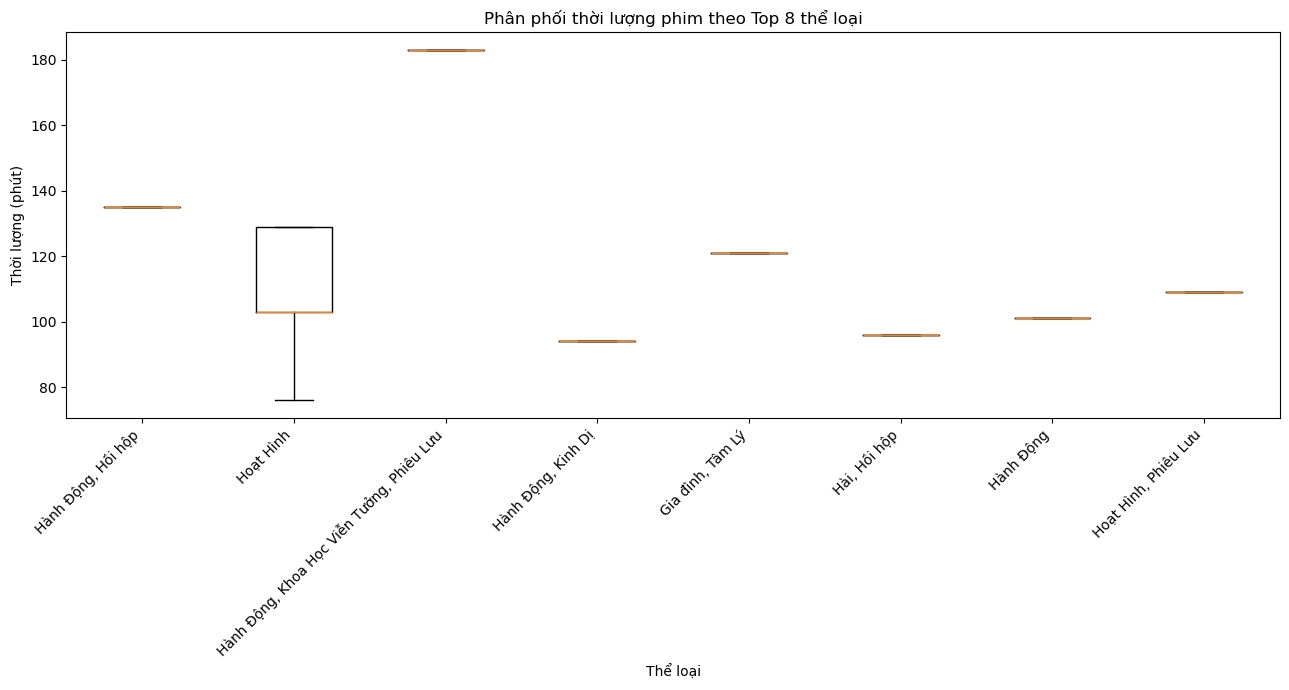

In [64]:
if 'Genre' in df.columns and 'DurationMinutes' in df.columns:
    temp = df[['Genre', 'DurationMinutes']].copy()
    temp['DurationMinutes'] = pd.to_numeric(temp['DurationMinutes'], errors='coerce')
    temp = temp.dropna()
    
    top_genres = temp['Genre'].astype(str).value_counts().head(8).index
    temp = temp[temp['Genre'].astype(str).isin(top_genres)].copy()
    
    groups = []
    labels = []
    for g in top_genres:
        vals = temp.loc[temp['Genre'].astype(str) == g, 'DurationMinutes'].dropna().values
        if len(vals) > 0:
            groups.append(vals)
            labels.append(str(g))
            
    if groups:
        plt.figure(figsize=(13, 7))
        # Sử dụng tick_labels thay vì labels để tương thích với matplotlib mới
        plt.boxplot(groups, tick_labels=labels)
        plt.title('Phân phối thời lượng phim theo Top 8 thể loại')
        plt.xlabel('Thể loại')
        plt.ylabel('Thời lượng (phút)')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()
    else:
        print("Không đủ dữ liệu để vẽ Boxplot.")
else:
    print('Thiếu Genre hoặc DurationMinutes.')

### Nhận xét

- Nhóm 'Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu' dài nhất (183 phút), 'Hoạt Hình, Thần thoại' khoảng 144 phút, 'Hành Động, Hồi hộp' 135 phút; các nhóm hoạt hình khác ngắn hơn rõ rệt.
- Hộp của mỗi nhóm rất hẹp hoặc chỉ là một đường vì mỗi nhóm chỉ gồm một vài phim với thời lượng cố định; kết luận so sánh chỉ mang tính mô tả.

# 12. Checklist sản phẩm

| Yêu cầu | Kết quả |
|---|---|
| Dữ liệu đã làm sạch và xuất CSV | Đã thực hiện |
| Ít nhất 5 biểu đồ đơn biến, đa biến | Có 6 biểu đồ |
| Tiêu đề, nhãn trục và nhận xét | Đã bổ sung |


# 13. Kết luận EDA

- Bộ dữ liệu sạch: 1.172 suất chiếu, 5 rạp, 14 phim, 10 ngày, **không có giá trị thiếu**.
- Ngoại lệ IQR ở `TicketPrice`, `TotalSeats`, `AvailableSeats` đều **hợp lệ về nghiệp vụ** (phòng đặc biệt, cỡ phòng khác nhau) nên giữ nguyên.
- Lịch chiếu lệch mạnh về vài phim (3 phim đầu chiếm ~62% số suất) nên `DurationMinutes` và `Genre` phản ánh cơ cấu phim hơn là một biến liên tục.
- Giá vé tăng theo phòng đặc biệt và suất tối, tỉ lệ lấp đầy trung bình khoảng 34%, cao hơn ở suất tối và cuối tuần. Các quan hệ này **do quy luật giả định trong dữ liệu mô phỏng**, nên chỉ chứng minh pipeline học lại được quy luật, không phải nhu cầu thật của CGV.